# Secciones de Poincaré — medición de tiempos de cómputo

Este cuaderno reproduce, celda por celda, los tres sistemas forzados de la
Sección 2.6.2 de la tesis (*Análisis cualitativo: retratos de fase y
secciones de Poincaré*). El propósito es que el jurado pueda ejecutar cada
bloque de manera independiente y verificar el tiempo de cómputo real que
toma generar cada sección de Poincaré densa.

Cada celda de cómputo usa la magia `%%time` de Jupyter/IPython, que reporta
el tiempo de CPU y el tiempo de pared (*wall time*) al finalizar la celda.
**No se guardan las figuras en disco** — solo se muestran en pantalla
(`plt.show()`), ya que aquí el objetivo es únicamente medir el desempeño;
los archivos PDF finales se generan por separado con
`secciones_poincare.py` (ver Apéndice A.3).

**Advertencia:** cada uno de los tres sistemas integra una malla de
80–100 condiciones iniciales durante 500 periodos de forzamiento cada una,
por lo que cada celda puede tardar varios minutos, dependiendo del equipo.

In [5]:
%matplotlib inline

In [6]:
%%time
import numpy as np
from scipy.integrate import solve_ivp
import matplotlib.pyplot as plt
import matplotlib as mpl

# Estilo global de las figuras (consistente con el resto de la tesis)
mpl.rcParams.update({
    "font.family": "serif",
    "mathtext.fontset": "cm",
    "font.size": 11,
    "axes.labelsize": 12,
    "axes.titlesize": 12,
    "figure.dpi": 110,
})

CPU times: total: 0 ns
Wall time: 103 μs


## 1. Péndulo forzado y amortiguado

$$
\dot{x} = v, \qquad \dot{v} = -c\,v - \sin x + F\cos(\omega t)
$$

con $c=0.05$, $\omega=0.7$, $F=0.6$. La sección de Poincaré se construye
integrando una malla de $8\times10$ condiciones iniciales durante 500
periodos de forzamiento $T=2\pi/\omega$, registrando la posición
$(\theta,\dot\theta)$ del sistema cada vez que $t$ cruza un múltiplo entero
de $T$ (evento disparado por `solve_ivp` cuando $\sin(\omega t)$ cruza cero
con derivada positiva).

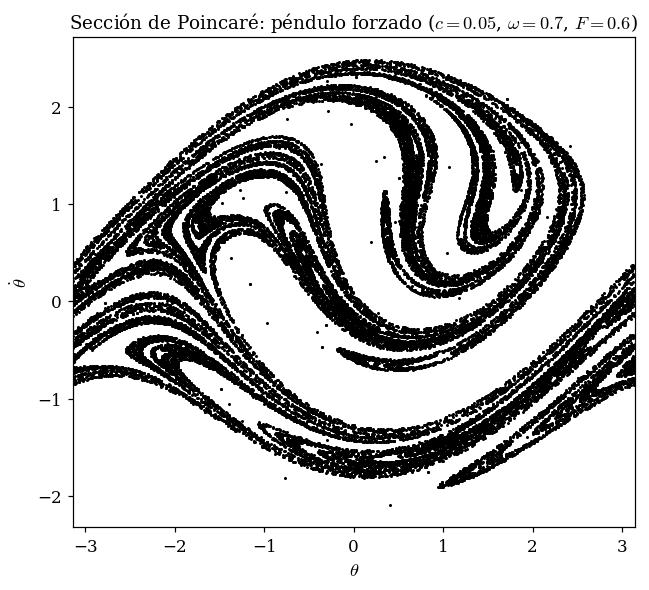

CPU times: total: 9min
Wall time: 10min 5s


In [7]:
%%time
c = 0.05
omega = 0.7
F = 0.6
T = 2 * np.pi / omega

def pendulo(t, y):
    x, v = y
    return [v, -c * v - np.sin(x) + F * np.cos(omega * t)]

def evento_poincare(t, y):
    return np.sin(omega * t)

evento_poincare.direction = 1
evento_poincare.terminal = False

# Malla de condiciones iniciales en el espacio fase
n_theta, n_v = 8, 10
theta_vals = np.linspace(-np.pi, np.pi, n_theta)
v_vals = np.linspace(-2.0, 2.0, n_v)
Theta_grid, V_grid = np.meshgrid(theta_vals, v_vals)
E_theta = Theta_grid.flatten()
E_v = V_grid.flatten()

n_periods = 500
t_max = n_periods * T

theta_all, v_all = [], []

for theta0, v0 in zip(E_theta, E_v):
    sol = solve_ivp(
        pendulo, (0, t_max), [theta0, v0],
        method="DOP853", events=evento_poincare,
        rtol=1e-9, atol=1e-9,
    )
    if len(sol.y_events[0]) > 0:
        theta_ev = sol.y_events[0][:, 0]
        v_ev = sol.y_events[0][:, 1]
        # se descarta el primer cruce (condición inicial, no estacionario)
        theta_ev = theta_ev[1:]
        v_ev = v_ev[1:]
        theta_ev = (theta_ev + np.pi) % (2 * np.pi) - np.pi
        theta_all.append(theta_ev)
        v_all.append(v_ev)

theta_all = np.concatenate(theta_all)
v_all = np.concatenate(v_all)

fig, ax = plt.subplots(figsize=(6, 5.5))
ax.scatter(theta_all, v_all, s=1, color="black")
ax.set_xlabel(r"$\theta$")
ax.set_ylabel(r"$\dot{\theta}$")
ax.set_title(
    r"Sección de Poincaré: péndulo forzado "
    rf"($c={c}$, $\omega={omega}$, $F={F}$)"
)
ax.set_xlim(-np.pi, np.pi)
fig.tight_layout()
plt.show()

## 2. Oscilador de van der Pol–Duffing forzado

$$
\ddot{x} - \mu(1-x^2)\dot{x} + \frac{dV_1(x)}{dx} = A_1\cos(\omega_1 t),
\qquad
V_1(x) = \tfrac{1}{2}\gamma x^2 + \tfrac{1}{3}\eta x^3 + \tfrac{1}{4}\varepsilon x^4
$$

con $\mu=0.6$, $\gamma=-1$, $\eta=-0.8$, $\varepsilon=1$, $A_1=1$,
$\omega_1=1.5$. Igual que en el caso anterior, se integra una malla
$8\times10$ de condiciones iniciales durante 500 periodos de forzamiento
$T=2\pi/\omega_1$.

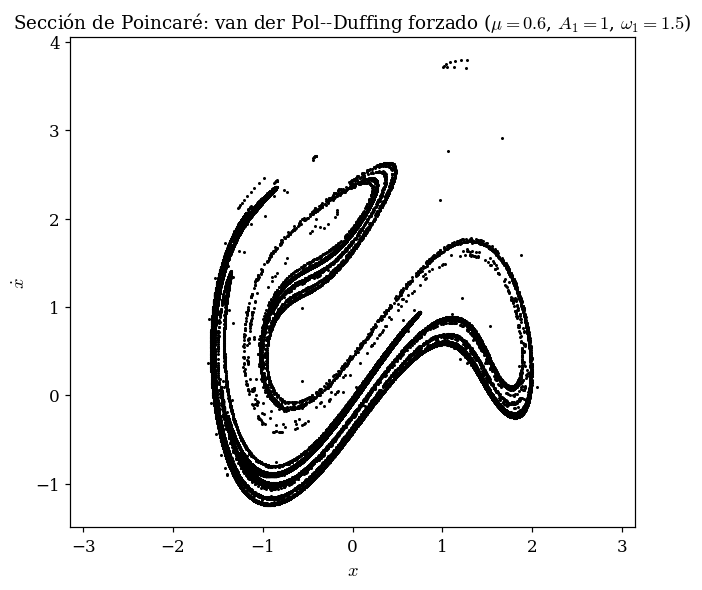

CPU times: total: 3min 47s
Wall time: 4min 5s


In [8]:
%%time
mu = 0.6
gamma = -1
eta = -0.8
epsilon = 1
A1 = 1
omega1 = 1.5
T = 2 * np.pi / omega1

def van_der_pol_duffing(t, y):
    x, v = y
    return [
        v,
        mu * (1 - x**2) * v - gamma * x - eta * (x**2) - epsilon * (x**3)
        + A1 * np.cos(omega1 * t),
    ]

def evento_poincare(t, y):
    return np.sin(omega1 * t)

evento_poincare.direction = 1
evento_poincare.terminal = False

n_theta, n_v = 8, 10
theta_vals = np.linspace(-np.pi, np.pi, n_theta)
v_vals = np.linspace(-2.0, 2.0, n_v)
Theta_grid, V_grid = np.meshgrid(theta_vals, v_vals)
E_theta = Theta_grid.flatten()
E_v = V_grid.flatten()

n_periods = 500
t_max = n_periods * T

theta_all, v_all = [], []

for theta0, v0 in zip(E_theta, E_v):
    sol = solve_ivp(
        van_der_pol_duffing, (0, t_max), [theta0, v0],
        method="DOP853", events=evento_poincare,
        rtol=1e-9, atol=1e-9,
    )
    if len(sol.y_events[0]) > 0:
        theta_ev = sol.y_events[0][:, 0]
        v_ev = sol.y_events[0][:, 1]
        theta_ev = theta_ev[1:]
        v_ev = v_ev[1:]
        theta_ev = (theta_ev + np.pi) % (2 * np.pi) - np.pi
        theta_all.append(theta_ev)
        v_all.append(v_ev)

theta_all = np.concatenate(theta_all)
v_all = np.concatenate(v_all)

fig, ax = plt.subplots(figsize=(6, 5.5))
ax.scatter(theta_all, v_all, s=1, color="black")
ax.set_xlabel(r"$x$")
ax.set_ylabel(r"$\dot{x}$")
ax.set_title(
    r"Sección de Poincaré: van der Pol--Duffing forzado "
    rf"($\mu={mu}$, $A_1={A1}$, $\omega_1={omega1}$)"
)
ax.set_xlim(-np.pi, np.pi)
fig.tight_layout()
plt.show()

## 3. Oscilador $\Phi^6$ de Duffing forzado

$$
\ddot{y} + \sigma\dot{y} + \frac{dV_2(y)}{dy} = A_2\cos(\omega_2 t),
\qquad
V_2(y) = \tfrac{1}{2}\alpha y^2 + \tfrac{1}{4}\beta y^4 + \tfrac{1}{6}\delta y^6
$$

con $\sigma=0.05$, $\alpha=1$, $\beta=-0.6$, $\delta=0.06$, $A_2=4$,
$\omega_2=0.5$. Aquí la malla de condiciones iniciales es $10\times10$
(100 trayectorias en total), también integradas durante 500 periodos de
forzamiento $T=2\pi/\omega_2$ — es, de los tres, el sistema
computacionalmente más costoso.

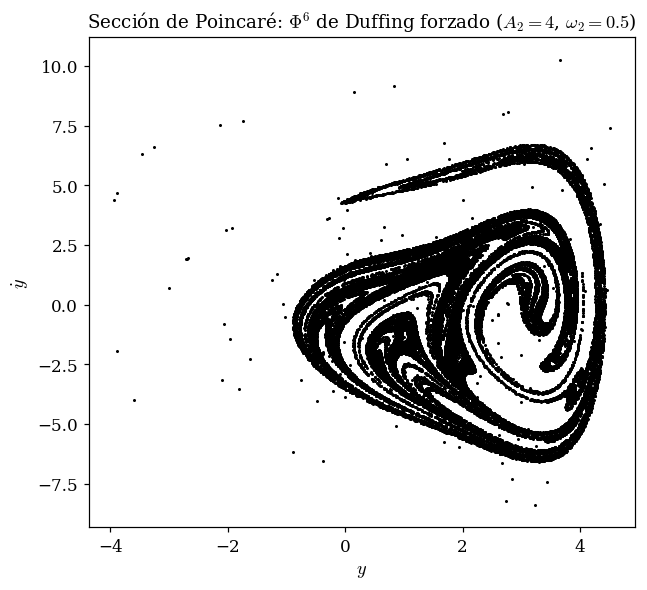

CPU times: total: 16min 34s
Wall time: 17min 40s


In [10]:
%%time
sigma = 0.05
alpha = 1
beta = -0.6
delta = 0.06
A2 = 4
omega2 = 0.5
T = 2 * np.pi / omega2

def phi6_duffing(t, x):
    y, v = x
    return [
        v,
        -sigma * v - alpha * y - beta * (y**3) - delta * (y**5)
        + A2 * np.cos(omega2 * t),
    ]

def evento_poincare(t, y):
    return np.sin(omega2 * t)

evento_poincare.direction = 1
evento_poincare.terminal = False

n_theta, n_v = 10, 10
theta_vals = np.linspace(-5, 5, n_theta)
v_vals = np.linspace(-6.0, 6.0, n_v)
Theta_grid, V_grid = np.meshgrid(theta_vals, v_vals)
E_theta = Theta_grid.flatten()
E_v = V_grid.flatten()

n_periods = 500
t_max = n_periods * T

theta_all, v_all = [], []

for theta0, v0 in zip(E_theta, E_v):
    sol = solve_ivp(
        phi6_duffing, (0, t_max), [theta0, v0],
        method="DOP853", events=evento_poincare,
        rtol=1e-9, atol=1e-9,
    )
    if len(sol.y_events[0]) > 0:
        theta_ev = sol.y_events[0][:, 0]
        v_ev = sol.y_events[0][:, 1]
        theta_ev = theta_ev[1:]
        v_ev = v_ev[1:]
        theta_ev = ((theta_ev + 2.5 * np.pi) % (5 * np.pi)) - 2.5 * np.pi
        theta_all.append(theta_ev)
        v_all.append(v_ev)

theta_all = np.concatenate(theta_all)
v_all = np.concatenate(v_all)

fig, ax = plt.subplots(figsize=(6, 5.5))
ax.scatter(theta_all, v_all, s=1, color="black")
ax.set_xlabel(r"$y$")
ax.set_ylabel(r"$\dot{y}$")
ax.set_title(
    r"Sección de Poincaré: $\Phi^6$ de Duffing forzado "
    rf"($A_2={A2}$, $\omega_2={omega2}$)"
)
fig.tight_layout()
plt.show()

## Notas sobre los tiempos de cómputo

- El tiempo reportado por `%%time` corresponde únicamente a la integración
  numérica y al trazado de la figura de esa celda; no incluye el tiempo de
  arranque del kernel de Python ni la importación de librerías (celda 1).
- Los tres sistemas usan el mismo integrador (`DOP853`) y las mismas
  tolerancias ($\mathrm{rtol}=\mathrm{atol}=10^{-9}$); las diferencias de
  tiempo entre celdas reflejan principalmente el tamaño de la malla de
  condiciones iniciales y la rigidez/complejidad de cada sistema.
- Para una demostración en vivo más rápida (a costa de una sección menos
  densa), se puede reducir `n_periods` (por ejemplo a 100) y el tamaño de
  la malla (`n_theta`, `n_v`) en cualquiera de las tres celdas, sin
  modificar el resto del código.
- Las figuras finales en PDF que aparecen en la tesis (Sección 2.6.2) se
  generaron con `secciones_poincare.py` (Apéndice A.3), usando exactamente
  estos mismos parámetros.